---
numbering: false
---

# 3.6: Inverses

In [Chapter 3.4](03-04.ipynb), we saw matrices stretch, rotate, reflect, and project vectors. Some of those operations can be undone; others lose information. Here, we'll connect the idea of **undoing a transformation** to the algebra of a matrix inverse.

Our goal is to understand what an inverse must do, find inverses in simple cases, and use them to solve equations. We'll return to the broader question of which matrices are invertible soon.

---

## What is an inverse?

With numbers, a multiplicative inverse is a number that multiplies with the original to give 1. For instance, the inverse of 2 is $\frac12$, because

$$2\left(\frac12\right)=\left(\frac12\right)2=1.$$

For matrices, the identity matrix plays the role of 1. Recall that $I_n$ leaves every vector in $\mathbb R^n$ unchanged, and $I_nA=AI_n=A$ for an $n\times n$ matrix $A$.

:::{note} Definition: Inverse
An $n\times n$ matrix $A$ is **invertible** if there is an $n\times n$ matrix $A^{-1}$ satisfying **both**

$$\boxed{AA^{-1}=I_n\qquad\text{and}\qquad A^{-1}A=I_n.}$$

We call $A^{-1}$ the **inverse** of $A$. A square matrix that has no inverse is called **singular**.
:::

The result must be the identity matrix in **both orders**. For square matrices, however, checking one order is enough: if $A$ and $B$ both have shape $n\times n$ and $AB=I_n$, then $BA=I_n$ as well. Thus, if a candidate for $A^{-1}$ gives $AA^{-1}=I_n$, the other order automatically gives $A^{-1}A=I_n$. These are matrix products, not products of entries in matching positions. In particular, finding $A^{-1}$ does **not** mean replacing each entry of $A$ by its reciprocal.

We'll use the word "inverse" in this sense for square matrices. Being square allows a matrix to be invertible, but doesn't guarantee that it is; projection onto the $x$-axis will give us a counterexample below.

### Can a matrix have more than one inverse?

No. Suppose $B$ and $C$ both satisfy the definition for $A$. Then

$$B=BI_n=B(AC)=(BA)C=I_nC=C.$$

So **the inverse, when it exists, is unique**. The definition also tells us that

$$I_n^{-1}=I_n,\qquad (A^{-1})^{-1}=A.$$

The second identity says that the inverse of the inverse is the original matrix: each one undoes the other.

---

## The inverse of a $2\times2$ matrix

For $2\times2$ matrices, we have a convenient formula:

:::{important} Inverse of a $2\times2$ matrix
Let $A=\begin{bmatrix}a&b\\c&d\end{bmatrix}$. Then $A$ is invertible **if and only if** $ad-bc\ne0$. When this holds,

$$\boxed{A^{-1}=\frac1{ad-bc}\begin{bmatrix}d&-b\\-c&a\end{bmatrix}.}$$
:::

In words: exchange the diagonal entries, negate the off-diagonal entries, and divide the whole matrix by $ad-bc$. The number $ad-bc$ is called the **determinant** of this $2\times2$ matrix. We'll study determinants more later; for now, this expression tells us whether the formula can be used.

### Why does the formula work?

Set $M=\begin{bmatrix}d&-b\\-c&a\end{bmatrix}$. Multiplying in each order gives

$$\begin{aligned}
AM&=\begin{bmatrix}ad-bc&-ab+ba\\cd-dc&-cb+da\end{bmatrix}
=(ad-bc)I_2,\\
MA&=\begin{bmatrix}da-bc&db-bd\\-ca+ac&-cb+ad\end{bmatrix}
=(ad-bc)I_2.
\end{aligned}$$

If $ad-bc\ne0$, dividing $M$ by that number makes both products equal $I_2$, exactly as the inverse definition requires. If $ad-bc=0$, the matrix is singular, and division by zero cannot produce an inverse.

### An example

Take

$$A=\begin{bmatrix}2&1\\1&1\end{bmatrix}.$$

Here, $ad-bc=2(1)-1(1)=1$, so

$$A^{-1}=\begin{bmatrix}1&-1\\-1&2\end{bmatrix}.$$

Let's check both products. We don't strictly need to check both: for square matrices, if one order gives the identity, so does the other. But checking both is a good habit, since order matters in matrix multiplication in general:

$$\begin{aligned}
AA^{-1}&=\begin{bmatrix}2&1\\1&1\end{bmatrix}
\begin{bmatrix}1&-1\\-1&2\end{bmatrix}
=\begin{bmatrix}1&0\\0&1\end{bmatrix},\\
A^{-1}A&=\begin{bmatrix}1&-1\\-1&2\end{bmatrix}
\begin{bmatrix}2&1\\1&1\end{bmatrix}
=\begin{bmatrix}1&0\\0&1\end{bmatrix}.
\end{aligned}$$

On the other hand, $\begin{bmatrix}1&2\\2&4\end{bmatrix}$ has $ad-bc=4-4=0$, so it is singular. Its second column is twice its first, which will matter when we discuss linear independence.

---

## Undoing a transformation

What do the two identities in the definition mean geometrically? If we apply $A$ to a vector and then apply $A^{-1}$, we get the original vector back:

$$\vec x\xrightarrow{\ A\ }A\vec x
\xrightarrow{\ A^{-1}\ }A^{-1}(A\vec x)=\vec x.$$

This is the meaning of $A^{-1}A=I_n$. The other identity, $AA^{-1}=I_n$, says that starting with $A^{-1}$ and then applying $A$ also returns the original vector.

For the example above,

$$\begin{bmatrix}1\\0\end{bmatrix}\xrightarrow{\ A\ }
\begin{bmatrix}2\\1\end{bmatrix}\xrightarrow{\ A^{-1}\ }
\begin{bmatrix}1\\0\end{bmatrix},\qquad
\begin{bmatrix}0\\1\end{bmatrix}\xrightarrow{\ A\ }
\begin{bmatrix}1\\1\end{bmatrix}\xrightarrow{\ A^{-1}\ }
\begin{bmatrix}0\\1\end{bmatrix}.$$

The columns of $A$ tell us where the standard basis vectors go. The inverse sends those outputs back to the corresponding basis vectors. It also returns **every other point** to its original position, as the picture shows.


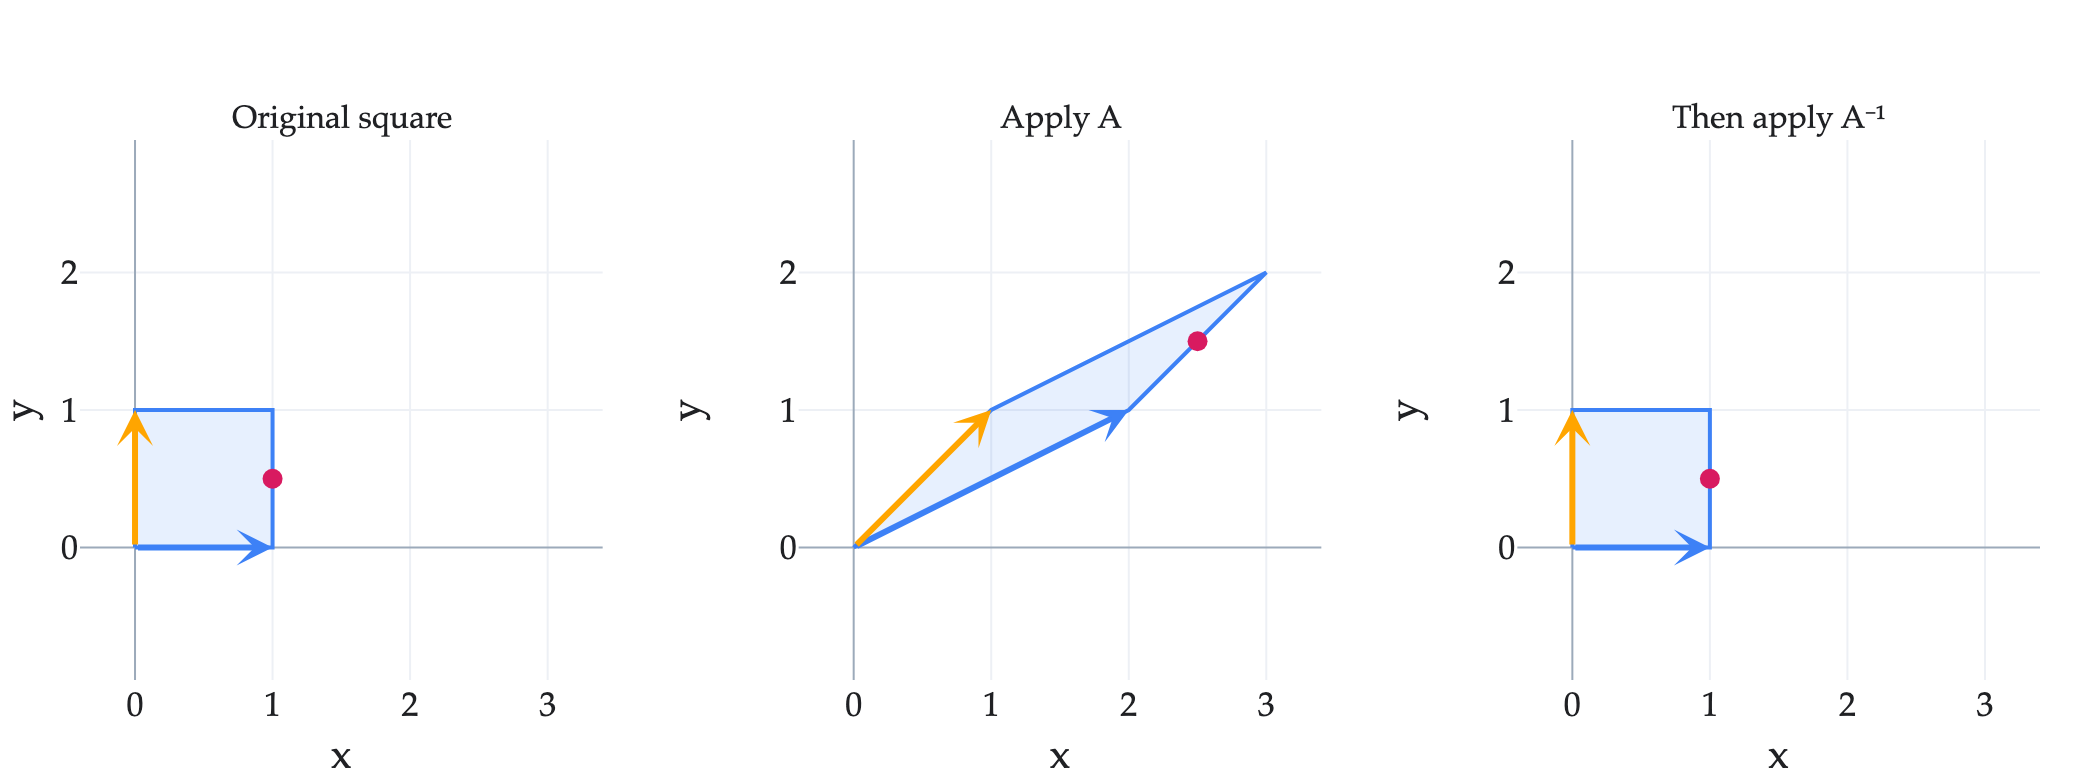

In [1]:
from pathlib import Path
import base64
import html
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import HTML, display

if hasattr(pio.defaults, 'headers'):
    pio.defaults.headers = {}

_inverse_A = np.array([[2, 1], [1, 1]])
_inverse_square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])
_inverse_point = np.array([1, 0.5])
_inverse_fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.10,
    subplot_titles=['Original square', 'Apply A', 'Then apply A⁻¹'])
_inverse_colors = ['#3d81f6', 'orange', '#d81a60']
for _col, _matrix in [(1, np.eye(2)), (2, _inverse_A), (3, np.linalg.inv(_inverse_A) @ _inverse_A)]:
    _points = _inverse_square @ _matrix.T
    _inverse_fig.add_trace(go.Scatter(x=_points[:, 0], y=_points[:, 1],
        mode='lines', fill='toself', fillcolor='rgba(61,129,246,0.12)',
        line=dict(color=_inverse_colors[0], width=2), hoverinfo='skip'), row=1, col=_col)
    _suffix = '' if _col == 1 else str(_col)
    for _k, _color in enumerate(_inverse_colors[:2]):
        _end = _matrix[:, _k]
        _inverse_fig.add_annotation(x=_end[0], y=_end[1], ax=0, ay=0,
            xref='x' + _suffix, yref='y' + _suffix,
            axref='x' + _suffix, ayref='y' + _suffix,
            text='', showarrow=True, arrowhead=3, arrowwidth=3, arrowcolor=_color)
    _point = _matrix @ _inverse_point
    _inverse_fig.add_trace(go.Scatter(x=[_point[0]], y=[_point[1]], mode='markers',
        marker=dict(color=_inverse_colors[2], size=10), hoverinfo='skip'), row=1, col=_col)
    _inverse_fig.update_xaxes(range=[-0.4, 3.4], dtick=1, title_text='x', row=1, col=_col)
    _inverse_fig.update_yaxes(range=[-0.4, 2.4], dtick=1, title_text='y',
        scaleanchor='x' + _suffix, scaleratio=1, row=1, col=_col)
_inverse_fig.update_layout(template='none', width=1040, height=390,
    paper_bgcolor='white', plot_bgcolor='white', showlegend=False,
    font=dict(family="Palatino, 'Palatino Linotype', serif", size=17, color='#202124'),
    margin=dict(l=40, r=20, t=70, b=50))
_inverse_fig.update_xaxes(gridcolor='#edf0f5', zerolinecolor='#9caaba')
_inverse_fig.update_yaxes(gridcolor='#edf0f5', zerolinecolor='#9caaba')
_inverse_png = _inverse_fig.to_image(format='png', scale=2)
_notes_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'myst.yml').exists())
_inverse_folder = _notes_root / 'ch03' / 'visuals'
_inverse_folder.mkdir(exist_ok=True)
(_inverse_folder / 'inverse-transformation.png').write_bytes(_inverse_png)
_inverse_alt = 'A unit square becomes a parallelogram under A, then returns to the same square under A inverse. Blue and orange arrows follow the standard basis vectors, and a pink point returns to its original position.'
_inverse_caption = 'The inverse returns every point to its original position. Blue and orange track the standard basis vectors; pink tracks another point in the square.'
display(HTML('<figure style="margin:16px 0"><img style="width:100%;height:auto" alt="'
    + html.escape(_inverse_alt, quote=True) + '" src="data:image/png;base64,'
    + base64.b64encode(_inverse_png).decode('ascii') + '"><figcaption style="margin-top:8px">'
    + html.escape(_inverse_caption) + '</figcaption></figure>'))

### Stretching and rotating

If $H=\begin{bmatrix}2&0\\0&1\end{bmatrix}$ doubles the horizontal coordinate, undoing it means halving that coordinate:

$$H^{-1}=\begin{bmatrix}1/2&0\\0&1\end{bmatrix}.$$

If $R_\theta$ rotates counterclockwise by $\theta$, its inverse rotates by $-\theta$:

$$R_\theta^{-1}=R_{-\theta}
=\begin{bmatrix}\cos\theta&\sin\theta\\-\sin\theta&\cos\theta\end{bmatrix}.$$

A reflection across the $x$-axis is another useful example: reflecting twice returns every point to where it started, so that matrix is its own inverse.

### Why a projection has no inverse

Projection onto the $x$-axis uses

$$P=\begin{bmatrix}1&0\\0&0\end{bmatrix}.$$

It sends both $\begin{bmatrix}1\\2\end{bmatrix}$ and $\begin{bmatrix}1\\5\end{bmatrix}$ to $\begin{bmatrix}1\\0\end{bmatrix}$. Given only this output, an inverse would have to recover two different original inputs from the same vector. A function can't do that!

Algebraically, if $P^{-1}$ existed, multiplying the equation $P\vec x=P\vec y$ on the left by $P^{-1}$ would give $\vec x=\vec y$. Our two inputs are different, so this is impossible.

**An invertible transformation must preserve enough information to recover every input.** In fact, for every $\vec b\in\mathbb R^n$, there is exactly one $\vec x\in\mathbb R^n$ with $A\vec x=\vec b$: it is $\vec x=A^{-1}\vec b$.

---

## Which matrices are invertible?

We've seen a formula for $2\times2$ matrices. What about larger square matrices?

:::{important} A preview
A square matrix is invertible **if and only if its columns are linearly independent**.
:::

Roughly, linear independence means that no column can be written as a linear combination of the others. In our singular example $\begin{bmatrix}1&2\\2&4\end{bmatrix}$, the second column is twice the first, so the columns are not linearly independent.

For a square matrix, independent columns give us a transformation that can be undone. We'll define linear independence carefully and explore this connection more soon. For now, we can use the inverse identities and the $2\times2$ formula without developing that theory.

---

## The inverse of a product

Suppose $A$ and $B$ are invertible square matrices of the same shape. In [Chapter 3.5](03-05.ipynb), we saw that $AB$ applies $B$ first and then $A$. To undo both steps, which inverse should act first?

We need to undo the **last** step first: apply $A^{-1}$, then $B^{-1}$. The matrix for those two steps is $B^{-1}A^{-1}$.

:::{important} Inverse of a product
If $A$ and $B$ are invertible square matrices of the same shape, then $AB$ is invertible and

$$\boxed{(AB)^{-1}=B^{-1}A^{-1}.}$$

Invert each factor **and reverse their order**.
:::

Let's verify both identities, keeping the factors in order and using associativity. Again, one check would suffice because these matrices are square, but it doesn't hurt to check both:

$$\begin{aligned}
(AB)(B^{-1}A^{-1})&=A(BB^{-1})A^{-1}=AI_nA^{-1}=I_n,\\
(B^{-1}A^{-1})(AB)&=B^{-1}(A^{-1}A)B=B^{-1}I_nB=I_n.
\end{aligned}$$

Both products are the identity, so $B^{-1}A^{-1}$ satisfies the inverse definition.

For example, let $H$ be our horizontal stretch and $R=\begin{bmatrix}0&-1\\1&0\end{bmatrix}$ our $90^\circ$ counterclockwise rotation. Stretching first, then rotating, uses $RH$. Undoing this means rotating clockwise first, then halving the horizontal coordinate:

$$(RH)^{-1}=H^{-1}R^{-1}
=\begin{bmatrix}1/2&0\\0&1\end{bmatrix}
\begin{bmatrix}0&1\\-1&0\end{bmatrix}
=\begin{bmatrix}0&1/2\\-1&0\end{bmatrix}.$$

The reversed order is essential: undo the last transformation first.

---

## Solving equations with inverses

With numbers, we might solve $2x=5$ by dividing by 2. With matrices, we multiply by an inverse. **We need to choose the correct side**, so that the matrix and its inverse appear next to each other.

### A vector equation

If $A$ is invertible and $A\vec x=\vec b$, multiply both sides on the left by $A^{-1}$:

$$A^{-1}(A\vec x)=A^{-1}\vec b
\quad\Longrightarrow\quad
\boxed{\vec x=A^{-1}\vec b.}$$

For our earlier matrix $A$, solving

$$\begin{bmatrix}2&1\\1&1\end{bmatrix}\vec x
=\begin{bmatrix}5\\3\end{bmatrix}$$

gives

$$\vec x=\begin{bmatrix}1&-1\\-1&2\end{bmatrix}
\begin{bmatrix}5\\3\end{bmatrix}
=\begin{bmatrix}2\\1\end{bmatrix}.$$

Substituting this vector into the original equation gives $\begin{bmatrix}5\\3\end{bmatrix}$, as required.

### A matrix equation

The same reasoning works when the unknown is a matrix $X$. If $AX=B$, then

$$A^{-1}(AX)=A^{-1}B
\quad\Longrightarrow\quad
\boxed{X=A^{-1}B.}$$

If instead $XA=B$, multiply on the **right**:

$$(XA)A^{-1}=BA^{-1}
\quad\Longrightarrow\quad
\boxed{X=BA^{-1}.}$$

In each case, assume $A$ is invertible and the shapes allow the original equation. The two answers have different orders because the unknown appears on different sides of $A$.

For example, if $AXB=C$, where $A$ and $B$ are invertible and all matrices have shape $n\times n$, multiply on the left by $A^{-1}$ and on the right by $B^{-1}$:

$$A^{-1}(AXB)B^{-1}=A^{-1}CB^{-1}
\quad\Longrightarrow\quad
X=A^{-1}CB^{-1}.$$

We haven't moved any factors past one another. We've placed the inverses where they can cancel with their corresponding matrices.

:::{tip} Activity: Undo, then check
:class: dropdown

1. Find the inverse of $\begin{bmatrix}1&2\\0&1\end{bmatrix}$ using the $2\times2$ formula. Explain what its transformation undoes.
2. Is $\begin{bmatrix}3&6\\1&2\end{bmatrix}$ invertible? Explain using the formula and the relationship between its columns.
3. Let $A$, $B$, and $C$ have shape $n\times n$, with $A$ and $B$ invertible. Solve $AXB=C$ for $X$, then check your answer by substitution.
4. If $A$ is invertible and $A\vec x=A\vec y$, explain why $\vec x=\vec y$. What goes wrong with this argument for a projection?
:::